# Scientific evaluation of Claude models on translational cancer biology tasks

**Shu Chen — Postdoctoral Scholar, UCSF**

This notebook reproduces the analysis of a small, blinded pilot evaluation. Haiku 5.5, Sonnet 5.5 and Opus 5.5 answered six tasks drawn from experimental and translational prostate cancer work, and every response was scored blind against a predefined rubric and failure taxonomy.

**Questions**

1. Which tasks did each requested model answer, and which did it refuse?
2. On the tasks every model answered, how do the scores compare?
3. Which capabilities and failure modes separate the models?
4. Do answer length or stated confidence track the author score?

The notebook reads only files committed to this repository (tasks, raw outputs, blind scores and the blinding key). It makes no API calls. The model runs themselves are in `scripts/run_models.py`.

## 1. Setup

The notebook looks for the repository root in the current folder and its parents. If it is opened outside a clone, it downloads the committed repository files from GitHub once and caches them in `claude-scientific-eval-main/` next to the notebook.

Set `SAVE = True` to overwrite the tables and figures in `results/`. By default the notebook only displays them and checks them against the committed versions.

In [1]:
from pathlib import Path
import json
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

REPO_ZIP = "https://github.com/Shu-Chenzy/claude-scientific-eval/archive/refs/heads/main.zip"


def find_root(start):
    # The repository root is the first folder (here or above) that holds tasks/ and the blind scores.
    for d in [start, *start.parents]:
        if (d / "tasks").is_dir() and (d / "scoring" / "blind_scores.csv").exists():
            return d
    return None


ROOT = find_root(Path.cwd().resolve())
if ROOT is None:
    # Opened outside a clone: fetch the committed repository files from GitHub once and cache them here.
    import io, urllib.request, zipfile
    ROOT = Path.cwd() / "claude-scientific-eval-main"
    if find_root(ROOT) is None:
        print("repository files not found locally; downloading", REPO_ZIP)
        with urllib.request.urlopen(REPO_ZIP) as r:
            zipfile.ZipFile(io.BytesIO(r.read())).extractall(Path.cwd())
assert find_root(ROOT) == ROOT, f"tasks/ and scoring/blind_scores.csv not found under {ROOT}"

TASKS, OUTPUTS, SCORING, RES = ROOT / "tasks", ROOT / "outputs", ROOT / "scoring", ROOT / "results"
FIG = RES / "figures"
SAVE = False

CORE = [
    "biological_correctness",
    "evidence_grounding",
    "causal_reasoning",
    "experimental_feasibility",
    "falsifiability",
    "uncertainty_calibration",
]
FCODES = [f"F{i:02d}" for i in range(1, 16)]
REQUESTED = ["claude-haiku-5-5", "claude-sonnet-5-5", "claude-opus-5-5"]
SHORT = {
    "claude-haiku-5-5": "Haiku 5.5",
    "claude-sonnet-5-5": "Sonnet 5.5",
    "claude-opus-5-5": "Opus 5.5",
    "claude-opus-5": "Opus 5 fallback",
}
ORDER = [SHORT[m] for m in REQUESTED]
ARMS = ORDER + ["Opus 5 fallback"]

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 300,
    "font.size": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
pd.set_option("display.max_colwidth", 120)
print("tasks found:", len(list(TASKS.glob("T*.json"))), "| scored responses file:", (SCORING / "blind_scores.csv").exists())

tasks found: 6 | scored responses file: True


## 2. Tasks

Each task bundles several related questions so that one answer exercises a whole step of the scientific decision loop. `expected_elements` are the concrete points a strong answer should contain and serve as per-task scoring anchors.

In [2]:
tasks = {p.stem: json.loads(p.read_text(encoding="utf-8")) for p in sorted(TASKS.glob("T*.json"))}
pd.DataFrame([
    {
        "task": t["task_id"],
        "capability": t["capability"],
        "title": t["title"],
        "expected elements": len(t["expected_elements"]),
        "prompt version": t["prompt_version"],
        "input": t["input_version"],
    }
    for t in tasks.values()
]).set_index("task")

,capability,title,expected elements,prompt version,input
task,,,,,
T1,Evidence grounding,"Separate evidence, inference and speculation",6,v1.0,prostate_public_packet v0.1
T2,Mechanistic and causal reasoning,Competing mechanisms and the limits of causal inference,6,v1.0,prostate_public_packet v0.1
T3,Target prioritization,Prioritize candidates under uncertainty and resource limits,6,v1.0,prostate_public_packet v0.1
T4,"Experimental design, controls and falsifiability",Minimum causal experiment with controls and a rescue arm,8,v1.0,prostate_public_packet v0.1
T5,Closed-loop scientific decision-making,Hypothesis to experiment to feedback,8,v1.0,prostate_public_packet v0.1
T6,Quantitative assay design,Quantify a low-abundance cell-surface GPCR,8,v1.0,prostate_public_packet v0.1


## 3. Model runs and refusals

Every model received the identical prompt, input packet and output schema at `effort: high`, each in a fresh context. Server-side refusal fallbacks were **disabled** in the primary arm, so a refusal is recorded as a refusal rather than silently answered by a different model. Each record logs the model that actually served the request.

In [3]:
def load_runs(arm):
    rows = []
    for p in sorted((OUTPUTS / arm).glob("T*.json")):
        r = json.loads(p.read_text(encoding="utf-8"))
        rows.append({
            "task": r["task_id"],
            "arm": arm,
            "requested": SHORT.get(r["model"], r["model"]),
            "served_by": SHORT.get(r["served_by"], r["served_by"]),
            "stop_reason": r["stop_reason"],
            "refused": r["refused"],
            "refusal_category": r.get("refusal_category"),
            "words": r["words"],
            "confidence": r["confidence"],
            "input_tokens": r.get("input_tokens"),
            "output_tokens": r.get("output_tokens"),
        })
    return rows


runs = pd.DataFrame(sum((load_runs(a) for a in REQUESTED), []))
status = runs.assign(status=np.where(runs.refused, "refused", "answered")).pivot(index="task", columns="requested", values="status")[ORDER]
status

requested,Haiku 5.5,Sonnet 5.5,Opus 5.5
task,,,
T1,answered,answered,answered
T2,answered,answered,answered
T3,answered,answered,refused
T4,answered,answered,refused
T5,answered,answered,refused
T6,answered,answered,refused


In [4]:
retries = pd.DataFrame([json.loads(p.read_text(encoding="utf-8")) for p in sorted((OUTPUTS / "claude-opus-5-5" / "retries").glob("*.json"))])
retry_table = (
    runs[runs.refused][["task", "requested", "refusal_category"]]
    .merge(
        retries.groupby("task_id").agg(repeat_attempts=("attempt", "size"), repeat_refused=("refused", "sum"),
                                         categories=("refusal_category", lambda s: ", ".join(sorted(set(s.dropna()))))),
        left_on="task", right_index=True, how="left",
    )
)
retry_table

,task,requested,refusal_category,repeat_attempts,repeat_refused,categories
14,T3,Opus 5.5,bio,2,2,bio
15,T4,Opus 5.5,bio,2,2,bio
16,T5,Opus 5.5,bio,2,2,bio
17,T6,Opus 5.5,bio,2,2,bio


Opus 5.5 answered T1–T2 and refused T3–T6. Those four tasks ask for target selection, experimental design, closed-loop planning and assay design. Every refusal carried the `bio` category and reproduced on two repeat attempts. A refusal is therefore a stable property of the model on these prompts, not sampling noise.

A separate, clearly labelled fallback arm was then run only for the refused prompts so that they could still be reviewed.

In [5]:
fallback_runs = pd.DataFrame(load_runs("claude-opus-5-5+fallback"))
fallback_runs[["task", "requested", "served_by", "stop_reason", "words", "confidence"]]

,task,requested,served_by,stop_reason,words,confidence
0,T3,Opus 5.5,Opus 5 fallback,end_turn,3632,62
1,T4,Opus 5.5,Opus 5 fallback,end_turn,1862,72
2,T5,Opus 5.5,Opus 5 fallback,end_turn,2782,65
3,T6,Opus 5.5,Opus 5 fallback,end_turn,3854,72


## 4. Blind scores and unblinding

Responses were presented as Model A, B and C, with labels **reshuffled independently on every task**. Six dimensions were scored 1–5 against written anchors (`scoring/rubric.md`), and every response was marked 0/1 on all 15 failure codes (`scoring/failure_taxonomy.md`). The blinding key was joined only after scoring was complete.

In [6]:
scores = pd.read_csv(SCORING / "blind_scores.csv")
key = pd.read_csv(RES / "blinding_key.csv")[["task_id", "label", "model", "arm", "served_by"]]

df = scores.merge(key, left_on=["task_id", "response"], right_on=["task_id", "label"], how="left", validate="one_to_one")
assert df.model.notna().all(), "every blinded response must map to a model"
for col in CORE + FCODES + ["confidence", "words"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")
df["mean_core"] = df[CORE].mean(axis=1)
df["requested_short"] = df.model.map(SHORT)
df["served_short"] = df.served_by.map(SHORT).fillna(df.served_by)
df["is_primary"] = (df.arm == df.model) & (df.served_by == df.model)

print(f"{len(df)} scored responses, {len(df) * len(CORE)} dimension scores, {len(df) * len(FCODES)} failure-code judgements")
print("primary-arm responses:", int(df.is_primary.sum()), "| fallback-arm responses:", int((~df.is_primary).sum()))

18 scored responses, 108 dimension scores, 270 failure-code judgements
primary-arm responses: 14 | fallback-arm responses: 4


The label shuffle can be checked directly: if labels were fixed, each model would sit in the same column on every task.

In [7]:
key.assign(model=key.model.map(SHORT) + np.where(key.arm != key.model, "*", "")).pivot(index="task_id", columns="label", values="model")

label,A,B,C
task_id,,,
T1,Sonnet 5.5,Haiku 5.5,Opus 5.5
T2,Haiku 5.5,Sonnet 5.5,Opus 5.5
T3,Opus 5.5*,Haiku 5.5,Sonnet 5.5
T4,Sonnet 5.5,Opus 5.5*,Haiku 5.5
T5,Opus 5.5*,Sonnet 5.5,Haiku 5.5
T6,Haiku 5.5,Opus 5.5*,Sonnet 5.5


\* fallback arm (served by Opus 5 after an Opus 5.5 refusal).

## 5. Primary arm

Primary responses are attributed to the model that answered them. Fallback answers are never folded into the requested model's mean, so the Opus 5.5 mean covers only the two tasks it answered.

In [8]:
primary = df[df.is_primary].copy()
fallback = df[~df.is_primary].copy()
refusals = pd.read_csv(RES / "refusals.csv")

rows = []
for m in REQUESTED:
    sub = primary[primary.model == m]
    rows.append({
        "model": SHORT[m],
        "primary_answered": len(sub),
        "primary_refused": int(refusals.loc[refusals.model == SHORT[m], "refused"].sum()),
        "mean_core_answered": sub.mean_core.mean() if len(sub) else np.nan,
        "mean_words_answered": sub.words.mean() if len(sub) else np.nan,
        "mean_confidence_answered": sub.confidence.mean() if len(sub) else np.nan,
        "failure_flags_primary": sub[FCODES].sum().sum() if len(sub) else 0,
    })
primary_summary = pd.DataFrame(rows).set_index("model")
primary_summary.round(2)

,primary_answered,primary_refused,mean_core_answered,mean_words_answered,mean_confidence_answered,failure_flags_primary
model,,,,,,
Haiku 5.5,6,0,4.14,1821.50,43.50,7
Sonnet 5.5,6,0,4.47,1771.67,53.33,6
Opus 5.5,2,4,4.58,2553.50,50.00,0


### Common-task comparison

Only tasks answered by all three requested models support a clean three-model score comparison.

In [9]:
counts = primary.groupby("task_id").model.nunique()
common_tasks = counts[counts == len(REQUESTED)].index.tolist()
common_summary = (
    primary[primary.task_id.isin(common_tasks)]
    .groupby("requested_short")
    .agg(n=("task_id", "size"), mean_core=("mean_core", "mean"), mean_words=("words", "mean"), mean_confidence=("confidence", "mean"))
    .reindex(ORDER)
)
print("common tasks:", ", ".join(common_tasks))
common_summary.round(2)

common tasks: T1, T2


,n,mean_core,mean_words,mean_confidence
requested_short,,,,
Haiku 5.5,2,4.42,1839.0,47.5
Sonnet 5.5,2,4.58,1728.5,51.0
Opus 5.5,2,4.58,2553.5,50.0


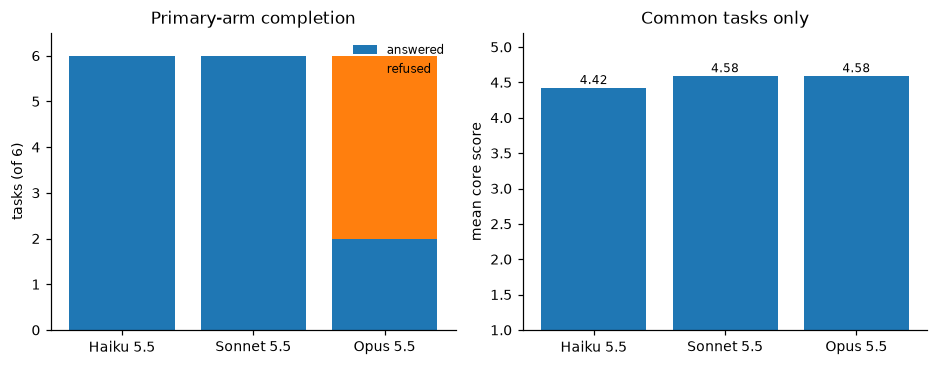

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(8.6, 3.4))
x = np.arange(len(primary_summary))
answered, refused = primary_summary.primary_answered.values, primary_summary.primary_refused.values
axes[0].bar(x, answered, label="answered")
axes[0].bar(x, refused, bottom=answered, label="refused")
axes[0].set_xticks(x, primary_summary.index)
axes[0].set_ylim(0, 6.5)
axes[0].set_ylabel("tasks (of 6)")
axes[0].set_title("Primary-arm completion")
axes[0].legend(frameon=False, fontsize=8)

vals = common_summary.mean_core.values
axes[1].bar(np.arange(len(common_summary)), vals)
axes[1].set_xticks(np.arange(len(common_summary)), common_summary.index)
axes[1].set_ylim(1, 5.2)
axes[1].set_ylabel("mean core score")
axes[1].set_title("Common tasks only")
for i, v in enumerate(vals):
    if pd.notna(v):
        axes[1].text(i, v + 0.06, f"{v:.2f}", ha="center", fontsize=8)
fig.tight_layout()
if SAVE:
    fig.savefig(FIG / "01_overall_model_performance.png", bbox_inches="tight")
plt.show()

With two common tasks the differences are descriptive only. Haiku 5.5 and Sonnet 5.5 answered all six tasks; I do not report a six-task Opus 5.5 mean.

## 6. Scores by dimension and capability

In [11]:
by_dim = primary.groupby("requested_short")[CORE].mean().reindex(ORDER)
by_dim.round(2)

,biological_correctness,evidence_grounding,causal_reasoning,experimental_feasibility,falsifiability,uncertainty_calibration
requested_short,,,,,,
Haiku 5.5,3.83,4.17,3.83,3.83,4.67,4.50
Sonnet 5.5,4.33,4.33,4.50,3.83,5.00,4.83
Opus 5.5,4.00,4.50,5.00,4.00,5.00,5.00


In [12]:
by_cap = primary.pivot_table(index="capability", columns="requested_short", values="mean_core").reindex(columns=ORDER)
by_cap.round(2)

requested_short,Haiku 5.5,Sonnet 5.5,Opus 5.5
capability,,,
Closed-loop scientific decision-making,4.50,4.50,NaN
Evidence grounding,4.67,4.67,4.67
"Experimental design, controls and falsifiability",4.00,4.67,NaN
Mechanistic and causal reasoning,4.17,4.50,4.50
Quantitative assay design,3.83,4.50,NaN
Target prioritization,3.67,4.00,NaN


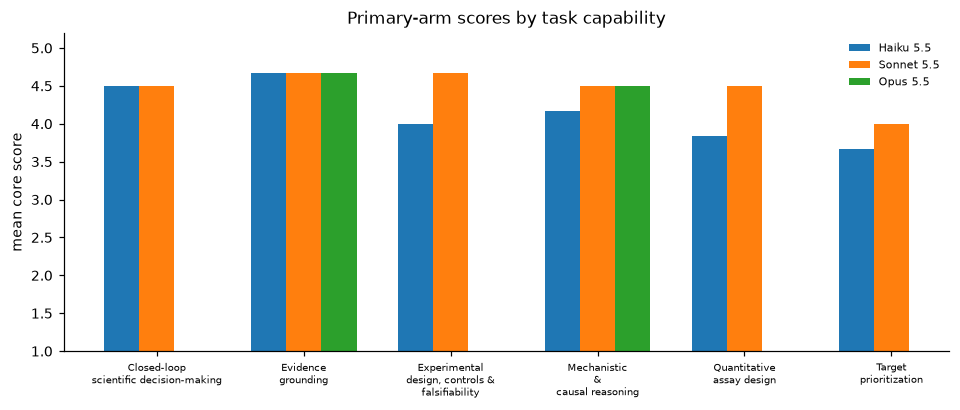

In [13]:
fig, ax = plt.subplots(figsize=(8.8, 3.8))
caps = list(by_cap.index)
x = np.arange(len(caps))
width = 0.24
for i, model in enumerate(by_cap.columns):
    ax.bar(x + (i - 1) * width, by_cap[model].values, width=width, label=model)
ax.set_xticks(x, [c.replace(" and ", " &\n").replace(" ", "\n", 1) for c in caps], fontsize=6.5)
ax.set_ylim(1, 5.2)
ax.set_ylabel("mean core score")
ax.set_title("Primary-arm scores by task capability")
ax.legend(frameon=False, fontsize=7)
fig.tight_layout()
if SAVE:
    fig.savefig(FIG / "02_by_capability.png", bbox_inches="tight")
plt.show()

Blank Opus 5.5 cells are primary-arm refusals, not missing analysis. Both Haiku 5.5 and Sonnet 5.5 scored lowest on target prioritization.

### Per-response score matrix

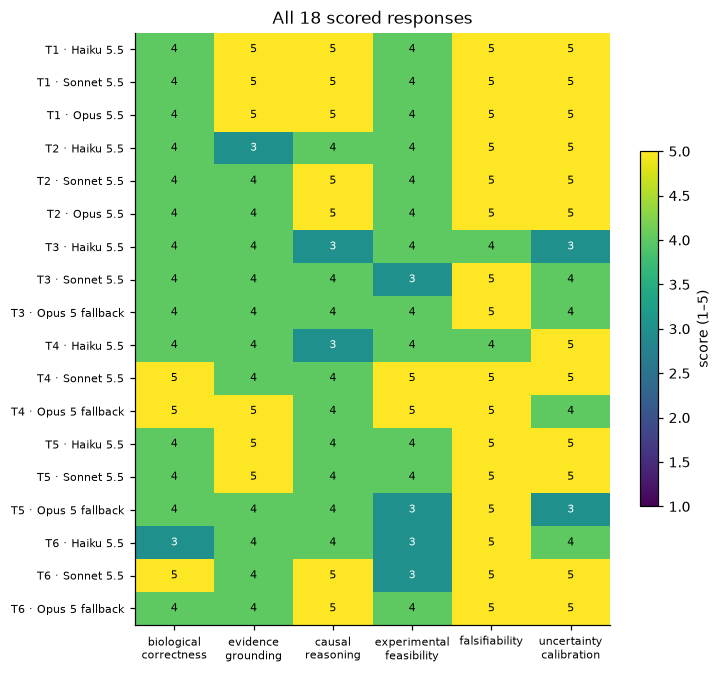

In [14]:
mat = df.assign(arm_label=np.where(df.is_primary, df.requested_short, df.served_short))
mat["arm_rank"] = mat.arm_label.map({a: i for i, a in enumerate(ARMS)})
mat = mat.sort_values(["task_id", "arm_rank"])
mat = mat.set_index(mat.task_id + " · " + mat.arm_label)[CORE].rename(columns=lambda c: c.replace("_", "\n"))
fig, ax = plt.subplots(figsize=(6.8, 6.2))
im = ax.imshow(mat.values, cmap="viridis", vmin=1, vmax=5, aspect="auto")
ax.set_xticks(range(mat.shape[1]), mat.columns, fontsize=7)
ax.set_yticks(range(mat.shape[0]), mat.index, fontsize=7)
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        ax.text(j, i, int(mat.values[i, j]), ha="center", va="center", fontsize=7, color="white" if mat.values[i, j] < 4 else "black")
fig.colorbar(im, ax=ax, shrink=0.6, label="score (1–5)")
ax.set_title("All 18 scored responses")
fig.tight_layout()
plt.show()

## 7. Failure modes

Every response is marked against all 15 codes, so failure counts are comparable between models.

In [15]:
taxonomy = {}
for line in (SCORING / "failure_taxonomy.md").read_text(encoding="utf-8").splitlines():
    m = re.match(r"\|\s*(F\d{2})\s*\|\s*([^|]+?)\s*\|", line)
    if m:
        taxonomy[m.group(1)] = m.group(2)

by_fail = primary.groupby("requested_short")[FCODES].sum().reindex(ORDER)
by_fail = by_fail.loc[:, by_fail.sum() > 0]
by_fail.T.assign(label=lambda d: d.index.map(taxonomy))[["label"] + ORDER]

requested_short,label,Haiku 5.5,Sonnet 5.5,Opus 5.5
F02,Unsupported mechanism,1,0,0
F05,Missing critical control,1,1,0
F06,Infeasible experiment,0,1,0
F07,Incorrect experimental logic,2,1,0
F11,Poor target prioritization,2,2,0
F13,Excessive / unnecessary experimentation,1,1,0


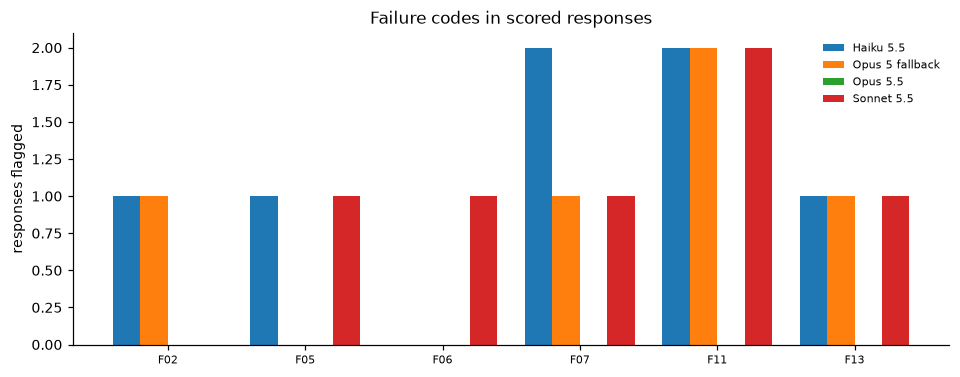

In [16]:
display_arms = pd.concat([
    primary.assign(analysis_arm=primary.requested_short),
    fallback.assign(analysis_arm=fallback.served_short),
], ignore_index=True)
fail = display_arms.groupby("analysis_arm")[FCODES].sum()
fail = fail.loc[:, fail.sum() > 0]

fig, ax = plt.subplots(figsize=(8.8, 3.5))
x = np.arange(fail.shape[1])
width = 0.8 / max(1, len(fail.index))
for i, arm in enumerate(fail.index):
    ax.bar(x - 0.4 + width / 2 + i * width, fail.loc[arm], width=width, label=arm)
ax.set_xticks(x, fail.columns, fontsize=7)
ax.set_ylabel("responses flagged")
ax.set_title("Failure codes in scored responses")
ax.legend(frameon=False, fontsize=7)
fig.tight_layout()
if SAVE:
    fig.savefig(FIG / "03_failure_modes.png", bbox_inches="tight")
plt.show()

In [17]:
flagged = display_arms[display_arms[FCODES].sum(axis=1) > 0]
pd.DataFrame([
    {"task": r.task_id, "response": r.analysis_arm,
     "codes": ", ".join(f"{c} {taxonomy[c]}" for c in FCODES if getattr(r, c) == 1)}
    for r in flagged.itertuples()
]).set_index(["task", "response"])

codes
task response                                                                                                                    
T2   Haiku 5.5                                                                                          F02 Unsupported mechanism
T3   Haiku 5.5                                                                                     F11 Poor target prioritization
     Sonnet 5.5                                                         F06 Infeasible experiment, F11 Poor target prioritization
T4   Sonnet 5.5                                                    F05 Missing critical control, F07 Incorrect experimental logic
     Haiku 5.5        F05 Missing critical control, F07 Incorrect experimental logic, F13 Excessive / unnecessary experimentation
T5   Sonnet 5.5                                       F11 Poor target prioritization, F13 Excessive / unnecessary experimentation
     Haiku 5.5                                                                                     F11 Poor target prioritization
T6   Haiku 5.5                                                                                   F07 Incorrect experimental logic
T3   Opus 5 fallback                                                                               F11 Poor target prioritization
T4   Opus 5 fallback                                                                             F07 Incorrect experimental logic
T5   Opus 5 fallback                                  F11 Poor target prioritization, F13 Excessive / unnecessary experimentation
T6   Opus 5 fallback                                                                                    F02 Unsupported mechanism

Two errors matter most for wet-lab decision-making:

- **Target prioritization (F11):** on T3 and T5, every scoreable response led with a candidate that did not meet the replication threshold in the supplied data, rather than the strongest reproducible signal.
- **Rescue interpretation (F07):** on T4, every scoreable response treated a failed rescue as stronger evidence against on-target causality than I would accept experimentally. A failed rescue can be technically ambiguous.

## 8. Fallback arm

These four answers were served by Claude Opus 5 after the Opus 5.5 refusal. They are reported for qualitative comparison only and are not Opus 5.5 measurements.

In [18]:
fallback_summary = (
    fallback.groupby(["requested_short", "served_short"])
    .agg(n=("task_id", "size"), mean_core=("mean_core", "mean"), mean_words=("words", "mean"), mean_confidence=("confidence", "mean"))
)
display(fallback_summary.round(2))
fallback[["task_id", "capability"] + CORE + ["mean_core"]].set_index("task_id").round(2)

,,n,mean_core,mean_words,mean_confidence
requested_short,served_short,,,,
Opus 5.5,Opus 5 fallback,4,4.29,3032.5,67.75


,capability,biological_correctness,evidence_grounding,causal_reasoning,experimental_feasibility,falsifiability,uncertainty_calibration,mean_core
task_id,,,,,,,,
T3,Target prioritization,4,4,4,4,5,4,4.17
T4,"Experimental design, controls and falsifiability",5,5,4,5,5,4,4.67
T5,Closed-loop scientific decision-making,4,4,4,3,5,3,3.83
T6,Quantitative assay design,4,4,5,4,5,5,4.50


## 9. Length, confidence and score

Across all 18 scored responses (both arms), does a longer or more confident answer score higher?

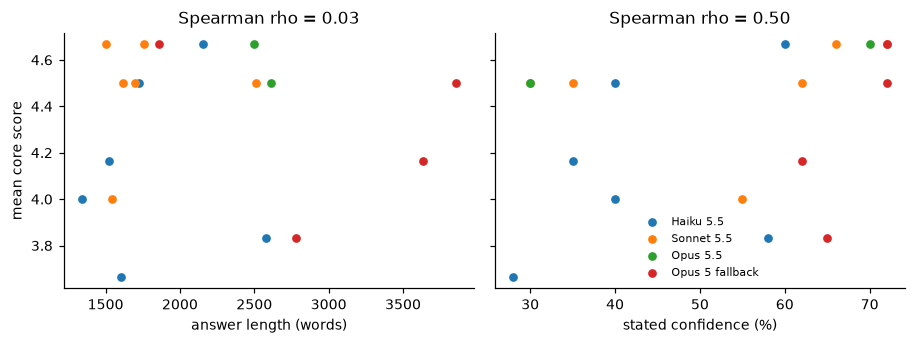

Confidence vs score: Spearman rho = 0.50
Length vs score:     Spearman rho = 0.03


In [19]:
allr = df[["confidence", "words", "mean_core"]].dropna()
rho_conf = allr.confidence.corr(allr.mean_core, method="spearman")
rho_len = allr.words.corr(allr.mean_core, method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(8.4, 3.2), sharey=True)
for ax, col, rho, xlabel in [(axes[0], "words", rho_len, "answer length (words)"),
                             (axes[1], "confidence", rho_conf, "stated confidence (%)")]:
    for arm in ARMS:
        sub = display_arms[display_arms.analysis_arm == arm]
        ax.scatter(sub[col], sub.mean_core, s=22, label=arm)
    ax.set_xlabel(xlabel)
    ax.set_title(f"Spearman rho = {rho:.2f}")
axes[0].set_ylabel("mean core score")
axes[1].legend(frameon=False, fontsize=7)
fig.tight_layout()
plt.show()
print(f"Confidence vs score: Spearman rho = {rho_conf:.2f}")
print(f"Length vs score:     Spearman rho = {rho_len:.2f}")

Answer length did not track score. Stated confidence had a moderate positive association, but with 18 responses this is descriptive, not inferential.

## 10. Reviewer notes

In [20]:
for tid, rows in df.sort_values(["task_id", "is_primary"], ascending=[True, False]).groupby("task_id", sort=True):
    lines = [f"**{tid} — {tasks[tid]['capability']}**", ""]
    for r in rows.itertuples():
        who = r.requested_short if r.is_primary else f"{r.served_short} (after {r.requested_short} refusal)"
        lines.append(f"- *{who}*, mean {r.mean_core:.2f}: {r.notes}")
    display(Markdown("\n".join(lines)))

**T1 — Evidence grounding**

- *Sonnet 5.5*, mean 4.67: Grounding is strong; several follow-up analyses depend on covariates not confirmed in the packet.
- *Haiku 5.5*, mean 4.67: Grounding is strong; the follow-up is feasible but under-specified for scale and replication.
- *Opus 5.5*, mean 4.67: Grounding is strong; several proposed reanalyses require data not shown in the packet.

**T2 — Mechanistic and causal reasoning**

- *Haiku 5.5*, mean 4.17: The causal framing is mostly sound, but it overstates the localized-tumor composition check as excluding composition in the resistant-disease contrast.
- *Sonnet 5.5*, mean 4.50: Causal reasoning is sound; some follow-up assays rely on data or scale not established in the packet.
- *Opus 5.5*, mean 4.50: Strong separation of exposure, selection, and causation; the follow-up is broader than the minimum needed.

**T3 — Target prioritization**

- *Haiku 5.5*, mean 3.67: The shortlist is reasonable, but the proposed CRISPRi direction does not match the fact that both leads are already reduced in resistant disease.
- *Sonnet 5.5*, mean 4.00: SSTR1 is prioritized despite weak replication and uncertain assay or reagent availability within the stated four-week window.Stronger database evidence is required to support SSTR1 before pursuing it further, rather than prioritizing a target based on my prompt or interest when the current data are not sufficiently supportive.
- *Opus 5 fallback (after Opus 5.5 refusal)*, mean 4.17: TONSL is elevated despite failed replication and sign reversal in SU2C; that negative evidence should weigh more heavily in prioritization.

**T4 — Experimental design, controls and falsifiability**

- *Sonnet 5.5*, mean 4.67: The interaction design is strong, but the positive assay control is optional and failed rescue is interpreted too strongly.
- *Haiku 5.5*, mean 4.00: The design is workable, but it lacks a clear positive resistance control, adds unnecessary experiments, and overinterprets failed rescue.
- *Opus 5 fallback (after Opus 5.5 refusal)*, mean 4.67: The minimal design is strong; failed rescue is treated as evidence against on-target causality rather than an ambiguous technical result.

**T5 — Closed-loop scientific decision-making**

- *Sonnet 5.5*, mean 4.50: Gating is clear, but SSTR1 remains the lead despite weaker replication; Step 0 does not change the decision.
- *Haiku 5.5*, mean 4.50: The plan is well gated, but the lead remains SSTR1 rather than a stronger replicated candidate.
- *Opus 5 fallback (after Opus 5.5 refusal)*, mean 3.83: Decision logic is clear, but SSTR1 is prioritized over stronger replicated signals and the plan expands beyond the minimum decision set.

**T6 — Quantitative assay design**

- *Haiku 5.5*, mean 3.83: Controls are comprehensive, but the receptor-density/ligand-occupancy logic is incorrect and the tag-based readout is impractical at low knock-in efficiency (e.g. HiBiT-based receptor detection).
- *Sonnet 5.5*, mean 4.50: The assay logic is strong, but practical constraints—especially low-efficiency knock-in—are underweighted (e.g. HiBiT-based receptor detection).
- *Opus 5 fallback (after Opus 5.5 refusal)*, mean 4.50: The quantitative design is strong; it imports sensitivity estimates and overstates what the composition analysis excludes.

## 11. Consistency with committed results

The tables computed above are compared with the files in `results/` produced by `scripts/analyze_blind.py`.

In [21]:
computed = {
    "model_summary.csv": primary_summary,
    "common_task_summary.csv": common_summary,
    "fallback_summary.csv": fallback_summary,
    "by_dimension.csv": by_dim,
    "by_capability.csv": by_cap,
    "failures_by_model.csv": by_fail,
}
check = []
for name, table in computed.items():
    ref = pd.read_csv(RES / name)
    mine = table.round(2).reset_index()
    mine.columns = ref.columns
    same = np.allclose(mine.select_dtypes("number").to_numpy(dtype=float), ref.select_dtypes("number").to_numpy(dtype=float), equal_nan=True)
    check.append({"file": f"results/{name}", "matches": same})
    if SAVE:
        table.round(2).to_csv(RES / name)
if SAVE:
    (RES / "common_tasks.txt").write_text("\n".join(common_tasks) + "\n", encoding="utf-8")
pd.DataFrame(check).set_index("file")

,matches
file,
results/model_summary.csv,True
results/common_task_summary.csv,True
results/fallback_summary.csv,True
results/by_dimension.csv,True
results/by_capability.csv,True
results/failures_by_model.csv,True


## Limitations

- Six tasks and one scorer; inter-rater reliability is not measured.
- One shared input packet limits task diversity.
- Only one generation per answered task was scored; sampling variability was not measured.
- Opus 5.5 refused four tasks, so only T1–T2 support a direct three-model score comparison.
- The four fallback answers were served by Opus 5 and are supplementary, not Opus 5.5 measurements.
- These tasks test a narrow slice of translational cancer biology and should not be generalized to scientific reasoning as a whole.